In [1]:
# project: p9
# submitter: askapuli
# partner: none
# hours: 7 


In [2]:
import csv
import copy 
import matplotlib
import pandas

# Allows you to render matplotlib graphs in the same notebook
%matplotlib inline 

def plot_dict(d, label="Please Label Me!!!"):
    ax = pandas.Series(d).sort_index().plot.bar(color="green", fontsize=16)
    ax.set_ylabel(label, fontsize=16)


In [3]:
#copied from p8 
#for opening csv files;

def process_csv(path):
    
    data = open(path, encoding = 'utf-8')
    csv_datafile = csv.reader(data)
    csv_list = list(csv_datafile)
    data.close()
    return csv_list


csv_data = process_csv('movies.csv')

data_header = csv_data[0]
data_body = csv_data[1:]

In [4]:
#copied from p8;

# Here are some functions which are useful for performing p8 and p9;
# loading a mapping file that can be used to lookup names from IDs;



def get_mapping(path):
    id_dict = {}
    csv_data = process_csv(path) # you can use this function from p7
    
    # TODO: make a dictionary where keys are the ID's and values are the names
    for item in csv_data:
        key = item[0]
        val = item[1]
        id_dict[key] = val
    return id_dict

In [5]:
#copied from p8;

# loading movie data with info represented using IDs;

def get_raw_movies(path):
    
    movie_dictList = []

    raw_data = process_csv(path)
    data_header = raw_data[0]
    data_body = raw_data[1:]
    
    # Creating a list of dictionaries where keys are column IDs 
    # and values are cells of each rows;
    for i in range(len(data_body)):
        movie_dict = {}
        row_i = data_body[i]
        
        for j in range(len(data_header)):
            
            key = data_header[j]
            val = row_i[j]
            if key == 'year' or key == 'duration':
                val = int(val)
            elif key == 'rating':
                val = float(val)
            elif key == 'genres' or key == 'directors' or key == 'actors':
                val = val.split(', ')
           
            movie_dict[key] = val
        
        # Adding the new dict into the list of dicts;
        movie_dictList.append(movie_dict)
    
    return movie_dictList

In [6]:
#copied from p8;

# replacing alpha-numeric IDs with actual names for movies, actors, and directors;

def get_movies(raw_file, map_file):
    
    refined_dict_list = []
    
    # Loading the data from raw movie data file as list of ditcs 
    # and loading mapping file as a dict as well;
    raw_dict_list = get_raw_movies(raw_file)
    map_data_dict = get_mapping(map_file)
    
    for item in raw_dict_list:
        title_id = item['title']
        act_id = item['actors']
        dir_id = item['directors']
        
        # replace the title IDs with the actual names;
        if title_id in map_data_dict:
            real_name = map_data_dict[title_id]
            item['title'] = real_name

            refined_dict_list.append(item)
        else:
            print(title_id, 'data is missing!')
            continue
        
        # looping through all IDs of actors and 
        # replace them with real names;
        for i in range(len(act_id)):
            if act_id[i] in map_data_dict:
                real_name = map_data_dict[act_id[i]]
                item['actors'][i] = real_name
            else:
                print(act_id[i], 'data is missing!')
                continue
        
        # looping through all IDs of directors and 
        # replace them with real names;   
        for i in range(len(dir_id)):
            if dir_id[i] in map_data_dict:
                real_name = map_data_dict[dir_id[i]]
                item['directors'][i] = real_name 
            else:
                print(dir_id[i], 'data is missing!')
                continue

    return refined_dict_list


In [7]:
#copied from p8;

# You are *not* allowed to change this function

def search_bar(movies, keyword):
    '''given a list of movie dictionaries and a keyword, 
    returns a list of movies that contains the keyword'''
    idx = 0
    while idx < len(movies):
        movie = movies[idx]
        if (keyword not in movie['title']) and (keyword not in movie["genres"]) and  (keyword not in movie["directors"]) and (keyword not in movie["actors"]):
            movies.pop(idx)
        else:
            idx += 1
    return movies



In [8]:
movies = get_movies("movies.csv", "mapping.csv")


In [9]:
movies[0:3]

[{'title': 'They Live',
  'year': 1988,
  'genres': ['Action', 'Horror', 'Sci-Fi'],
  'duration': 94,
  'directors': ['John Carpenter'],
  'actors': ['Roddy Piper', 'Keith David', 'Meg Foster'],
  'rating': 7.3},
 {'title': 'Beyond Justice',
  'year': 2014,
  'genres': ['Crime', 'Thriller'],
  'duration': 86,
  'directors': ['Timothy Woodward Jr.'],
  'actors': ['Vinnie Jones', 'Mischa Barton'],
  'rating': 3.4},
 {'title': 'Dirty Beautiful',
  'year': 2015,
  'genres': ['Comedy', 'Drama', 'Romance'],
  'duration': 95,
  'directors': ['Tim Bartell'],
  'actors': ['Ricky Mabe', 'Jordan Monaghan', 'Conor Leslie', 'Darin Heames'],
  'rating': 5.5}]

In [10]:
#Q1: What is the average rating of the 'Lord of the Rings' trilogy, which was directed by 'Peter Jackson'?

trilogy_wanted = search_bar(copy.deepcopy(movies), 'Lord of the Rings')


rating_list = []

for film in trilogy_wanted:
    
    film_dir = film['directors']
    
    for i in range(len(film_dir)):
        
        if film_dir[i] == 'Peter Jackson':
            
            film_rating = film['rating']
            rating_list.append(film_rating)

rating_sum = sum(rating_list)
rating_count = len(rating_list)
mean_rating = rating_sum / rating_count

mean_rating


8.8

In [11]:
#copied from lab9;

def median(items):
    items.sort()
    if len(items) % 2 == 1:
        if len(items) == 1:
            return items[0]
        else:
            return items[len(items)//2 + 1]
            
    else:
        first_middle = items[(len(items) // 2) - 1]
        second_middle = items[len(items) // 2]
        median = (first_middle + second_middle)/2
        return median 

In [12]:
trial = [2]
median(trial)

2

In [13]:
#Q2: What is the median rating of all 'Mission: Impossible' movies?

mission = search_bar(copy.deepcopy(movies),'Mission: Impossible')
len(mission)

mission_rating = []

for film in mission:
    rating = film['rating']
    mission_rating.append(rating)
    
mission_rating.sort()

median(mission_rating)

7.25

In [14]:
#Q3: Find all the movies with least rating.

all_rating = []

def find_worst(movies):
    for film in movies:
        rating = film['rating']
        all_rating.append(rating)
    
    sorted_rating = sorted(all_rating)
    least_rating = sorted_rating[0]
    
    return [film for film in movies if film['rating'] == least_rating]

find_worst(movies)    

[{'title': 'Proud American',
  'year': 2008,
  'genres': ['Drama'],
  'duration': 115,
  'directors': ['Fred Ashman'],
  'actors': ['Michael G. Davis',
   'Cecelia Antoinette',
   'Marie Antoinette',
   'Michelle Ashman'],
  'rating': 1.1},
 {'title': 'Troy: The Resurrection of Aeneas',
  'year': 2018,
  'genres': ['Animation', 'Action', 'Adventure'],
  'duration': 60,
  'directors': ['Aeneas Middleton'],
  'actors': ['Aeneas Middleton', 'Hardley Davidson'],
  'rating': 1.1},
 {'title': 'Browncoats: Independence War',
  'year': 2015,
  'genres': ['Action', 'Sci-Fi', 'War'],
  'duration': 98,
  'directors': ['Francis Hamada'],
  'actors': ['Beth Bemis',
   'Richard Martinsen',
   'Will James Johnson',
   'Nathan Cosmo Rahn'],
  'rating': 1.1},
 {'title': 'The Time Machine (I Found at a Yardsale)',
  'year': 2011,
  'genres': ['Sci-Fi'],
  'duration': 84,
  'directors': ['Steven A. Sandt'],
  'actors': ['George Abdelmalak', 'Steven Ronald Brattman', 'Elise Caloca'],
  'rating': 1.1},
 {'

In [15]:
#Q4: Find the highest rated 'Toy Story' movies.

toy = search_bar(copy.deepcopy(movies),'Toy Story')

highest = 0
toy_list =[]

for film in toy:
    rating = film['rating']
    if rating > highest:
        highest = rating

for film in toy:    
    if film['rating'] == highest:
        toy_list.append(film)

toy_list
    
    

[{'title': 'Toy Story 3',
  'year': 2010,
  'genres': ['Animation', 'Adventure', 'Comedy'],
  'duration': 103,
  'directors': ['Lee Unkrich'],
  'actors': ['Tom Hanks', 'Tim Allen'],
  'rating': 8.3},
 {'title': 'Toy Story',
  'year': 1995,
  'genres': ['Animation', 'Adventure', 'Comedy'],
  'duration': 81,
  'directors': ['John Lasseter'],
  'actors': ['Tom Hanks', 'Tim Allen', 'Don Rickles'],
  'rating': 8.3}]

In [16]:
# Function suggestion:
# This function should take in the list of movies as well as a category 
# (i.e. 'title', 'year', 'duration', 'actors', 'directors', or 'genres'), 
# and bucketize the list of movies by this category.

def bucketize(movie_list, category):
    buckets = {}
    
    for movie in movie_list:
        category_value = movie[category] #TODO: Access the category value from a movie
        if type(category_value) == list:
            for i in range(len(category_value)):
                indi_value = category_value[i]
                
                if not indi_value in buckets:
                    buckets[indi_value] = []
                
                buckets[indi_value].append(movie)

        else:
            if not category_value in buckets:
                buckets[category_value] = []
                
            buckets[category_value].append(movie)
            
    return buckets



In [17]:
#Q5: Find the list of movies 'Chadwick Boseman' acted in.

bucket_actors = bucketize(movies, 'actors')

for actor in bucket_actors:
    if actor == 'Chadwick Boseman':
        film_list = bucket_actors[actor]
        
film_list


[{'title': 'Message from the King',
  'year': 2016,
  'genres': ['Action', 'Crime', 'Drama'],
  'duration': 102,
  'directors': ['Fabrice du Welz'],
  'actors': ['Chadwick Boseman', 'Luke Evans'],
  'rating': 6.4},
 {'title': 'Black Panther',
  'year': 2018,
  'genres': ['Action', 'Adventure', 'Sci-Fi'],
  'duration': 134,
  'directors': ['Ryan Coogler'],
  'actors': ['Chadwick Boseman', 'Michael B. Jordan', "Lupita Nyong'o"],
  'rating': 7.3},
 {'title': 'Get on Up',
  'year': 2014,
  'genres': ['Biography', 'Drama', 'Music'],
  'duration': 139,
  'directors': ['Tate Taylor'],
  'actors': ['Chadwick Boseman', 'Nelsan Ellis', 'Dan Aykroyd'],
  'rating': 6.9},
 {'title': '21 Bridges',
  'year': 2019,
  'genres': ['Action', 'Crime', 'Drama'],
  'duration': 99,
  'directors': ['Brian Kirk'],
  'actors': ['Chadwick Boseman', 'Sienna Miller', 'J.K. Simmons'],
  'rating': 6.6},
 {'title': '42',
  'year': 2013,
  'genres': ['Biography', 'Drama', 'Sport'],
  'duration': 128,
  'directors': ['B

In [18]:
#Q6: Find the list of movies 'Emma Stone' acted in.

for actor in bucket_actors:
    if actor == 'Emma Stone':
        film_list = bucket_actors[actor]
film_list


[{'title': 'The Croods',
  'year': 2013,
  'genres': ['Animation', 'Action', 'Adventure'],
  'duration': 98,
  'directors': ['Kirk DeMicco', 'Chris Sanders'],
  'actors': ['Nicolas Cage', 'Emma Stone'],
  'rating': 7.2},
 {'title': 'Marmaduke',
  'year': 2010,
  'genres': ['Comedy', 'Family'],
  'duration': 99,
  'directors': ['Tom Dey'],
  'actors': ['Owen Wilson',
   'Emma Stone',
   'George Lopez',
   'Christopher Mintz-Plasse'],
  'rating': 4.3},
 {'title': 'The Help',
  'year': 2011,
  'genres': ['Drama'],
  'duration': 146,
  'directors': ['Tate Taylor'],
  'actors': ['Emma Stone', 'Viola Davis', 'Bryce Dallas Howard'],
  'rating': 8.0},
 {'title': 'Easy A',
  'year': 2010,
  'genres': ['Comedy', 'Drama', 'Romance'],
  'duration': 92,
  'directors': ['Will Gluck'],
  'actors': ['Emma Stone', 'Penn Badgley', 'Amanda Bynes', 'Dan Byrd'],
  'rating': 7.0},
 {'title': 'Irrational Man',
  'year': 2015,
  'genres': ['Comedy', 'Drama', 'Romance'],
  'duration': 95,
  'directors': ['Wood

In [19]:
#Q7: Find the number of movies in each genre.

bucket_genres = bucketize(movies, 'genres')

film_by_genre = {}

for genre in bucket_genres:
    key = genre
    val = len(bucket_genres[genre])
    
    if not genre in film_by_genre:
        film_by_genre[key] = val
    else:
        film_by_genre[key] += val
               
film_by_genre

{'Action': 5611,
 'Horror': 5175,
 'Sci-Fi': 2148,
 'Crime': 5078,
 'Thriller': 5340,
 'Comedy': 11130,
 'Drama': 16410,
 'Romance': 5753,
 'History': 627,
 'Adventure': 3849,
 'Western': 1177,
 'Family': 1585,
 'Fantasy': 1537,
 'War': 779,
 'Sport': 565,
 'Biography': 1009,
 'Mystery': 2479,
 'Film-Noir': 647,
 'Music': 908,
 'Animation': 676,
 'Musical': 941,
 'Reality-TV': 1,
 'Documentary': 1,
 'News': 1}

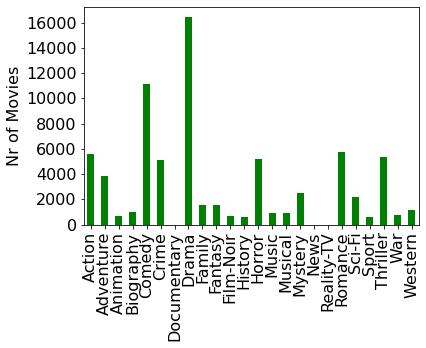

In [20]:
#Q8: Plot the number of movies in each genre as a bar graph.

plot_dict(film_by_genre, label = 'Nr of Movies')

#Some of the genres appear to have no bars in this plot. Can you figure out why that is the case?

#Number of movies in certain genres, such as News, Documentary, and Reality-TV, is too small to be seen in the plot;

In [21]:
#Q9: Find the number of movies released in each decade.

def year_to_decade(year):
    if year % 10 == 0:
        return str(year - 9) + " to " + str(year) # complete this line
    
    else:
        return str(year - year % 10 + 1) + " to " + str((year - year % 10) + 10) # complete this line

bucket_year = bucketize(movies, 'year')

film_in_decade = {}

for year in bucket_year:
    
    key = year_to_decade(year)
    val = len(bucket_year[year])

    if not key in film_in_decade:
        film_in_decade[key] = val
        
    else:
        film_in_decade[key] += val

film_in_decade


{'1981 to 1990': 2840,
 '2011 to 2020': 8884,
 '2001 to 2010': 6271,
 '1941 to 1950': 2256,
 '1971 to 1980': 1889,
 '1951 to 1960': 2201,
 '1931 to 1940': 2256,
 '1961 to 1970': 1609,
 '1991 to 2000': 4280,
 '1911 to 1920': 120,
 '1921 to 1930': 496}

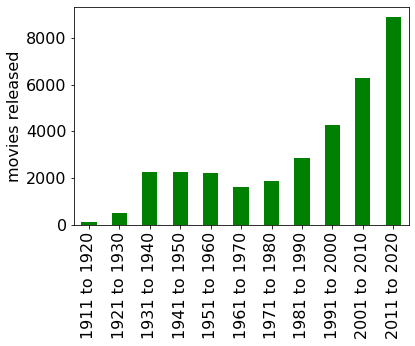

In [22]:
#Q10: Plot the number of movies released in each decade as a bar graph.

plot_dict(film_in_decade, label = 'movies released')

#Can you explain the peculiar shape of this plot? 
#Why is the number of movies in each decade not steadily increasing?

# In the 2nd and 3rd decades, film making technology was still in its infancy, and in the mid 20th century,
# there were economic depressions and WWII, which might have had negative impacts on the movie industry. 

In [23]:
#Q11: Find the highest rated movies for each genre.

best_film_by_genre = {}

for genre in bucket_genres:
    if not genre in best_film_by_genre:
        best_film_by_genre[genre] = []
        
    highest = 0
    for film in bucket_genres[genre]:
        
        if film['rating'] > highest:
            highest = film['rating']
        
    for film in bucket_genres[genre]:
        
        if film['rating'] == highest:
            best_film_by_genre[genre].append(film)

best_film_by_genre                  

{'Action': [{'title': 'The Dark Knight',
   'year': 2008,
   'genres': ['Action', 'Crime', 'Drama'],
   'duration': 152,
   'directors': ['Christopher Nolan'],
   'actors': ['Christian Bale',
    'Heath Ledger',
    'Aaron Eckhart',
    'Michael Caine'],
   'rating': 9.0}],
 'Horror': [{'title': 'Psycho',
   'year': 1960,
   'genres': ['Horror', 'Mystery', 'Thriller'],
   'duration': 109,
   'directors': ['Alfred Hitchcock'],
   'actors': ['Anthony Perkins', 'Vera Miles', 'John Gavin'],
   'rating': 8.5}],
 'Sci-Fi': [{'title': 'Inception',
   'year': 2010,
   'genres': ['Action', 'Adventure', 'Sci-Fi'],
   'duration': 148,
   'directors': ['Christopher Nolan'],
   'actors': ['Leonardo DiCaprio',
    'Joseph Gordon-Levitt',
    'Ellen Page',
    'Tom Hardy'],
   'rating': 8.8}],
 'Crime': [{'title': 'The Godfather',
   'year': 1972,
   'genres': ['Crime', 'Drama'],
   'duration': 175,
   'directors': ['Francis Ford Coppola'],
   'actors': ['Marlon Brando', 'Al Pacino'],
   'rating': 9.

In [24]:
#Q12: Find the median rating of movies from each genre.

median_rating_dict = {}

for genre in bucket_genres:
    if not genre in median_rating_dict:
        median_rating_dict[genre] = 0
        rating_list = []
        
        for film in bucket_genres[genre]:
            rating = film['rating']
            rating_list.append(rating)
    #print(len(rating_list))
    median_rating = median(rating_list)
    #print(median_rating)
    
    median_rating_dict[genre] = median_rating

median_rating_dict
            

{'Action': 5.5,
 'Horror': 4.6,
 'Sci-Fi': 4.9,
 'Crime': 6.0,
 'Thriller': 5.1,
 'Comedy': 5.9,
 'Drama': 6.1,
 'Romance': 6.2,
 'History': 6.5,
 'Adventure': 6.0,
 'Western': 6.2,
 'Family': 5.9,
 'Fantasy': 5.7,
 'War': 6.4,
 'Sport': 6.1,
 'Biography': 6.7,
 'Mystery': 5.8,
 'Film-Noir': 6.6,
 'Music': 6.2,
 'Animation': 6.4,
 'Musical': 6.2,
 'Reality-TV': 2.1,
 'Documentary': 7.5,
 'News': 6.4}

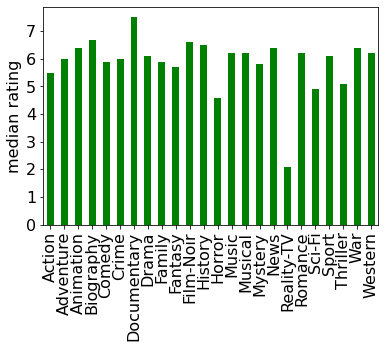

In [25]:
#Q13: Plot the median of movies in each genre as a bar graph.

plot_dict(median_rating_dict, label = 'median rating')

#Are you surprised by any of the median ratings here? 
#Can you explain why Documentaries and Reality-TV are such outliers?

# Because these genres only have a single rating, 
# and their median values do not reflect actual median of a list of values;b

In [26]:
#Q14: Sort the list of genres in decreasing order of their median rating.
list(dict(sorted(median_rating_dict.items(), key = lambda items: items[1], reverse = True)).keys())


['Documentary',
 'Biography',
 'Film-Noir',
 'History',
 'War',
 'Animation',
 'News',
 'Romance',
 'Western',
 'Music',
 'Musical',
 'Drama',
 'Sport',
 'Crime',
 'Adventure',
 'Comedy',
 'Family',
 'Mystery',
 'Fantasy',
 'Action',
 'Thriller',
 'Sci-Fi',
 'Horror',
 'Reality-TV']

In [27]:
#Q15: Sort all 'Star Wars' movies in increasing order of their year of release.

starWars_list = search_bar(copy.deepcopy(movies), 'Star Wars')

sorted(starWars_list, key = lambda d: d['year'])
    

[{'title': 'Star Wars',
  'year': 1977,
  'genres': ['Action', 'Adventure', 'Fantasy'],
  'duration': 121,
  'directors': ['George Lucas'],
  'actors': ['Mark Hamill', 'Harrison Ford', 'Carrie Fisher'],
  'rating': 8.6},
 {'title': 'Star Wars: Episode V - The Empire Strikes Back',
  'year': 1980,
  'genres': ['Action', 'Adventure', 'Fantasy'],
  'duration': 124,
  'directors': ['Irvin Kershner'],
  'actors': ['Mark Hamill', 'Harrison Ford'],
  'rating': 8.7},
 {'title': 'Star Wars: Episode VI - Return of the Jedi',
  'year': 1983,
  'genres': ['Action', 'Adventure', 'Fantasy'],
  'duration': 131,
  'directors': ['Richard Marquand'],
  'actors': ['Mark Hamill',
   'Harrison Ford',
   'Carrie Fisher',
   'Billy Dee Williams',
   'Anthony Daniels'],
  'rating': 8.3},
 {'title': 'Star Wars: Episode I - The Phantom Menace',
  'year': 1999,
  'genres': ['Action', 'Adventure', 'Fantasy'],
  'duration': 136,
  'directors': ['George Lucas'],
  'actors': ['Liam Neeson', 'Ewan McGregor', 'Natalie

In [28]:
#Q16: Find a list of all movies that are both acted and directed by 'Clint Eastwood'.
bucket_directors = bucketize(movies, 'directors')
bucket_actors = bucketize(movies, 'actors')

def dir_acted(person):
    
    dir_act_list = []

    for directed_film in bucket_directors[person]:
        for  acted_film in bucket_actors[person]:
            if directed_film == acted_film:
                dir_act_list.append(directed_film) 
    
    return dir_act_list
    
dir_acted('Clint Eastwood')            


[{'title': 'Space Cowboys',
  'year': 2000,
  'genres': ['Action', 'Adventure', 'Thriller'],
  'duration': 130,
  'directors': ['Clint Eastwood'],
  'actors': ['Clint Eastwood',
   'Tommy Lee Jones',
   'Donald Sutherland',
   'James Garner',
   'James Cromwell'],
  'rating': 6.4},
 {'title': 'Heartbreak Ridge',
  'year': 1986,
  'genres': ['Drama', 'War'],
  'duration': 130,
  'directors': ['Clint Eastwood'],
  'actors': ['Clint Eastwood', 'Marsha Mason', 'Everett McGill', 'Moses Gunn'],
  'rating': 6.9},
 {'title': 'Firefox',
  'year': 1982,
  'genres': ['Action', 'Adventure', 'Thriller'],
  'duration': 136,
  'directors': ['Clint Eastwood'],
  'actors': ['Clint Eastwood', 'Freddie Jones', 'David Huffman'],
  'rating': 6.0},
 {'title': 'The Rookie',
  'year': 1990,
  'genres': ['Action', 'Crime', 'Drama'],
  'duration': 120,
  'directors': ['Clint Eastwood'],
  'actors': ['Clint Eastwood', 'Charlie Sheen'],
  'rating': 5.9},
 {'title': 'Pale Rider',
  'year': 1985,
  'genres': ['Dram

In [29]:
#Q17: Sort the titles of the movies that are both acted and directed by 'Clint Eastwood'.
# Note: Your output should be a list of movie titles sorted in increasing order of their duration.

dir_acted_list = dir_acted('Clint Eastwood')
[d['title'] for d in sorted(dir_acted_list, key = lambda d: d['duration'])]

['Play Misty for Me',
 'High Plains Drifter',
 'The Gauntlet',
 'Blood Work',
 'White Hunter Black Heart',
 'Pale Rider',
 'Gran Torino',
 'The Mule',
 'Bronco Billy',
 'Sudden Impact',
 'The Rookie',
 'Absolute Power',
 'Honkytonk Man',
 'True Crime',
 'The Eiger Sanction',
 'Space Cowboys',
 'Heartbreak Ridge',
 'Unforgiven',
 'Million Dollar Baby',
 'The Bridges of Madison County',
 'The Outlaw Josey Wales',
 'Firefox',
 'A Perfect World']

In [30]:
#Q18: Sort the titles of the movies that are directed by both 'Anthony Russo' and 'Joe Russo' 
# in increasing order of their durations.

both_dir_list = []

for anthony_directed in bucket_directors['Anthony Russo']:
    for joe_directed in bucket_directors['Joe Russo']:
        if anthony_directed == joe_directed:
                both_dir_list.append(anthony_directed) 
                
[d['title'] for d in sorted(both_dir_list, key = lambda d: d['duration'])]                

['Welcome to Collinwood',
 'You, Me and Dupree',
 'Captain America: The Winter Soldier',
 'Captain America: Civil War',
 'Avengers: Infinity War',
 'Avengers: Endgame']

In [31]:
#Q19: Find the titles of the 15 shortest Biographies in the dataset.

film_len_list = []
for film in bucket_genres['Biography']:
    film_len_list.append(film['duration'])

film_title_dict = {}
film_title_list = []
film_len_list.sort()
for film in bucket_genres['Biography']:
    for i in range(15):
        if film_len_list[i] == film['duration']:
            film_wanted = film['title']
            if not film_wanted in film_title_dict:
                film_title_dict[film_wanted] = film['duration']

#print(film_title_dict)                
sorted_film_title = (sorted(film_title_dict.items(), key = lambda item: item[1]))
sorted_film_title_dict = dict(sorted_film_title)
list(sorted_film_title_dict.keys())

    

['Hibakusha',
 'King Candy',
 'Amy Winehouse: Fallen Star',
 'Steve Jobs: Visionary Genius',
 'The Road to Hollywood',
 'Danny Greene: The Rise and Fall of the Irishman',
 'From the Manger to the Cross; or, Jesus of Nazareth',
 'Joseph Smith: Prophet of the Restoration',
 'The Trade',
 'Blondes at Work',
 'Spirit of Youth',
 'The Loves of Edgar Allan Poe',
 'Alexander Hamilton',
 'Dillinger',
 'Memoria']

In [32]:
#Q20: Find the top 25 actors with the highest median rating among those actors who have acted in at least 15 movies.

actor_rating_dict = {}

for actor in bucket_actors:
        
    if len(bucket_actors[actor]) >= 15:
        if not actor in actor_rating_dict:
            actor_rating_dict[actor] = []
            
            for film in bucket_actors[actor]:
                rating = film['rating']
                actor_rating_dict[actor].append(rating)

median_rating_dict = {}                
for key, val in actor_rating_dict.items():
    val = sorted(val)
    median_val = median(val)
    if not key in median_rating_dict:
        median_rating_dict[key] = median_val
    
sorted_median_rating = sorted(median_rating_dict.items(), key = lambda item: item[1], reverse = True)
sorted_median_rating_dict = dict(sorted_median_rating)

best_actors = []
count = 0
for actor in sorted_median_rating_dict:
    count += 1
    if count <= 25:
        best_actors.append(actor)

best_actors
#sorted_median_rating_dict
         

['Audrey Hepburn',
 'Leonardo DiCaprio',
 'Ryan Gosling',
 'Ian McKellen',
 'Gena Rowlands',
 'Christian Bale',
 'Woody Allen',
 'Harold Lloyd',
 'Brad Pitt',
 'Philip Seymour Hoffman',
 'Ralph Fiennes',
 'Hugh Jackman',
 'Mia Farrow',
 'Laurence Olivier',
 'Cary Grant',
 'Tom Hanks',
 'Groucho Marx',
 'Arthur Kennedy',
 'Humphrey Bogart',
 'Amy Adams',
 'Jake Gyllenhaal',
 'Burt Lancaster',
 'Sissy Spacek',
 'Margaret Sullavan',
 'Judy Garland']